# Práctica 5: Neurona con error cuadrático y NumPy

## Objetivo
En este cuaderno se optimizará el cálculo del descenso por gradiente. En esta práctica se conserva el modelo $y = wx$ y se utiliza nuevamente el error cuadrático junto con descenso por gradiente[cite: 61]. Al igual que en la práctica anterior, las operaciones se realizarán aprovechando la vectorización de la biblioteca NumPy y los resultados se visualizarán con Matplotlib.

## Datos de Entrenamiento
Se definen los arreglos numéricos para las entradas y las salidas esperadas:
* Entradas ($x$): `np.array([1, 2, 3, 4])`[cite: 61]
* Salidas esperadas ($t$): `np.array([2, 4, 6, 8])`[cite: 61]

## Modelo Matemático y Vectorización del Gradiente

El modelo de predicción lineal se define como:
$$y = wx$$

### Función de Costo Cuadrático (Vectorizada)
A diferencia del perceptrón simple, aquí evaluamos el desempeño del modelo utilizando el Error Cuadrático Medio ($J$) sobre todo el conjunto de datos de entrenamiento. En lugar de iterar con un ciclo `for`, NumPy aplica la operación sobre arreglos completos[cite: 64, 65]. Para un arreglo de predicciones $p$ y salidas esperadas $t$, el error cuadrático individual es:
$$E = (y - t)^2$$

### Descenso por Gradiente y Regla de la Cadena
Para optimizar el parámetro $w$, debemos calcular la derivada de la función de error con respecto al peso ($\frac{\partial E}{\partial w}$)[cite: 22]. Aplicando la regla de la cadena:
$$\frac{\partial E}{\partial w} = \frac{\partial E}{\partial y} \cdot \frac{\partial y}{\partial w}$$

Desarrollando las derivadas parciales para cada elemento del arreglo:
1. Derivada del error respecto a la salida (almacenado como `errors_d`)[cite: 23, 24]:
   $$\frac{\partial E}{\partial y} = 2(y - t)$$
2. Derivada de la salida respecto al peso (sabiendo que $y = wx$)[cite: 23]:
   $$\frac{\partial y}{\partial w} = x$$
3. Derivada final del error respecto al peso para cada dato (almacenado como `weight_d`)[cite: 24]:
   $$\frac{\partial E}{\partial w} = 2(y - t)x$$

### Actualización del Parámetro
Finalmente, se calcula el gradiente promedio ($\frac{\partial J}{\partial w}$) utilizando `np.mean()` sobre el arreglo de derivadas obtenidas. La regla de actualización de descenso por gradiente se aplica para mover el peso en dirección opuesta a la pendiente del error[cite: 64, 65]:
$$w_{nuevo} = w_{anterior} - \eta \frac{\partial J}{\partial w}$$ ```  ***  Con esta versión, la celda de matemáticas queda muchísimo más técnica. Demuestra que no solo sabes aplicar operaciones con arreglos en NumPy, sino que entiendes la teoría del descenso por gradiente y la regla de la cadena que sustenta la librería.  <ElicitationsGroup message="Para pulir el aspecto visual de tus cuadernos en Kaggle:"> <Elicitation label="Revisar renderizado de ecuaciones" query="¿Me explicas cómo hace Kaggle para mostrar esas ecuaciones bonitas usando los signos de dólar ($$)?"/>
  <Elicitation label="Exportar a PDF" query="¿Se pueden guardar estos cuadernos de Kaggle directamente en PDF con las ecuaciones y las gráficas ya renderizadas?"/>
</ElicitationsGroup>

<FollowUp label="¿Qué te parece este nivel de detalle matemático?" query="¿Crees que con estas ecuaciones el profesor quede satisfecho con el nivel técnico de esta práctica en particular?"/>


EPOCA 1
Entrada:  1.0 | Target:   2.0 | Pred:   0.1000 | Error^2:   3.6100 | dE/dy:  -3.8000 | dE/dw:  -3.8000
Entrada:  2.0 | Target:   4.0 | Pred:   0.2000 | Error^2:  14.4400 | dE/dy:  -7.6000 | dE/dw: -15.2000
Entrada:  3.0 | Target:   6.0 | Pred:   0.3000 | Error^2:  32.4900 | dE/dy: -11.4000 | dE/dw: -34.2000
Entrada:  4.0 | Target:   8.0 | Pred:   0.4000 | Error^2:  57.7600 | dE/dy: -15.2000 | dE/dw: -60.8000
Costo promedio: 27.075000
Gradiente dJ/dw: -28.500000
Peso antes: 0.100000
Peso despues: 2.950000

EPOCA 2
Entrada:  1.0 | Target:   2.0 | Pred:   2.9500 | Error^2:   0.9025 | dE/dy:   1.9000 | dE/dw:   1.9000
Entrada:  2.0 | Target:   4.0 | Pred:   5.9000 | Error^2:   3.6100 | dE/dy:   3.8000 | dE/dw:   7.6000
Entrada:  3.0 | Target:   6.0 | Pred:   8.8500 | Error^2:   8.1225 | dE/dy:   5.7000 | dE/dw:  17.1000
Entrada:  4.0 | Target:   8.0 | Pred:  11.8000 | Error^2:  14.4400 | dE/dy:   7.6000 | dE/dw:  30.4000
Costo promedio: 6.768750
Gradiente dJ/dw: 14.250000
Peso ant

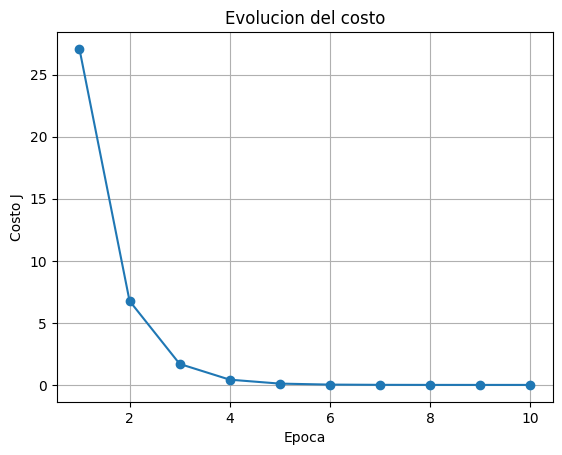

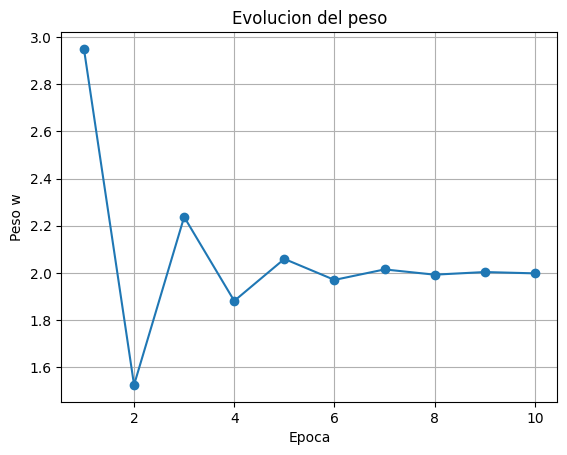

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

inputs = np.array([1, 2, 3, 4], dtype=float)
targets = np.array([2, 4, 6, 8], dtype=float)

w = 0.1
epochs = 10
learning_rate = 0.1
pause_time = 0.2

weight_history = []
cost_history = []

for epoch in range(epochs):
    
    predictions = w * inputs
    
    errors = (predictions - targets)**2
    
    cost = np.mean(errors)
    
    errors_d = 2 * (predictions - targets)
    
    weight_d = errors_d * inputs
    
    gradient = np.mean(weight_d)
    
    print("\n" + "=" * 65)
    print(f"EPOCA {epoch + 1}")
    print("=" * 65)
    
    for i, t, p, e, ed, wd in zip(inputs, targets, predictions, errors, errors_d, weight_d):
        print(
            f"Entrada: {i:>4.1f} | "
            f"Target: {t:>5.1f} | "
            f"Pred: {p:>8.4f} | "
            f"Error^2: {e:>8.4f} | "
            f"dE/dy: {ed:>8.4f} | "
            f"dE/dw: {wd:>8.4f}"
        )
        
    print(f"Costo promedio: {cost:.6f}")
    print(f"Gradiente dJ/dw: {gradient:.6f}")
    print(f"Peso antes: {w:.6f}")
    
    w -= learning_rate * gradient
    
    print(f"Peso despues: {w:.6f}")
    
    weight_history.append(w)
    cost_history.append(cost)
    
    time.sleep(pause_time)

test_inputs = np.array([5, 6], dtype=float)
test_targets = np.array([10, 12], dtype=float)

test_predictions = w * test_inputs

print("\n" + "=" * 65)
print("PRUEBA FINAL")
print("=" * 65)

for i, t, p in zip(test_inputs, test_targets, test_predictions):
    print(
        f"Entrada: {i:>4.1f} | "
        f"Target: {t:>5.1f} | "
        f"Prediccion: {p:>8.4f}"
    )

plt.figure()
plt.plot(range(1, epochs + 1), cost_history, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Costo J")
plt.title("Evolucion del costo")
plt.grid()
plt.show()

plt.figure()
plt.plot(range(1, epochs + 1), weight_history, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Peso w")
plt.title("Evolucion del peso")
plt.grid()
plt.show()

## Análisis de Resultados y Gráficas

La inclusión de Matplotlib nos permite observar el comportamiento dinámico del descenso por gradiente:
1. **Convergencia del Costo:** La gráfica de *Evolución del costo* muestra la disminución del costo cuadrático promedio durante el entrenamiento[cite: 65]. El valor cae drásticamente en las primeras épocas y se estabiliza rápidamente en cero, demostrando la alta eficiencia del algoritmo.
2. **Dinámica del Peso:** La gráfica de *Evolución del peso* revela un comportamiento muy interesante del gradiente: el peso oscila inicialmente alrededor del valor esperado y converge progresivamente hacia $w=2$[cite: 65]. Estas oscilaciones (como "rebotes") son características de una tasa de aprendizaje grande en funciones de costo empinadas, pero logran estabilizarse perfectamente antes de la décima época.